In [51]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [52]:
%autoreload 2

In [53]:
import sys
import os
from PIL import Image as PILImage
import torch
from torch import Tensor
import numpy as np
import skimage as sk

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

from rect_prune_ood.lib.util.data_loader import paths

In [54]:
severity = 5

def gaussian_noise(x: Tensor) -> Tensor:
    # print("gaussian_noise")
    c = [0.08, 0.12, 0.18, 0.26, 0.38][severity - 1]
    noise = torch.normal(mean=0.0, std=c, size=x.size()).to(x.dtype)
    x = x / 255.0
    x = (x + noise).clamp(0, 1) * 255
    return x.to(torch.float32)

def brightness(x: Tensor) -> Tensor:
    # print("brightness")
    # print(x.dtype)
    c = [0.1, 0.2, 0.3, 0.4, 0.5][severity - 1]
    x = x.permute(1, 2, 0).numpy()  # Convert to HWC format and numpy array
    x = x / 255.0
    x = sk.color.rgb2hsv(x)
    x[:, :, 2] = np.clip(x[:, :, 2] + c, 0, 1)
    x = sk.color.hsv2rgb(x)
    x = torch.tensor(x).permute(2, 0, 1)  # Convert back to CHW format
    return (x * 255).clip(0, 255).to(torch.float32)

def saturate(x: Tensor) -> Tensor:
    # print("saturate")
    c = [(0.3, 0), (0.1, 0), (2, 0), (5, 0.1), (20, 0.2)][severity - 1]
    x = x.permute(1, 2, 0).numpy()  # Convert to HWC format and numpy array
    x = x / 255.0
    x = sk.color.rgb2hsv(x)
    x[:, :, 1] = np.clip(x[:, :, 1] * c[0] + c[1], 0, 1)
    x = sk.color.hsv2rgb(x)
    x = torch.tensor(x).permute(2, 0, 1)  # Convert back to CHW format
    return (x * 255).clip(0, 255).to(torch.float32)

def pixelate(x: Tensor) -> Tensor:
    # print("pixelate")
    c = [0.6, 0.5, 0.4, 0.3, 0.25][severity - 1]
    x = x.permute(1, 2, 0).numpy()  # Convert to HWC format and numpy array
    img = PILImage.fromarray(x.astype(np.uint8))
    img = img.resize((int(224 * c), int(224 * c)), PILImage.BOX)
    img = img.resize((224, 224), PILImage.BOX)
    x = torch.tensor(np.array(img)).permute(2, 0, 1)  # Convert back to CHW format
    return x.to(torch.float32)

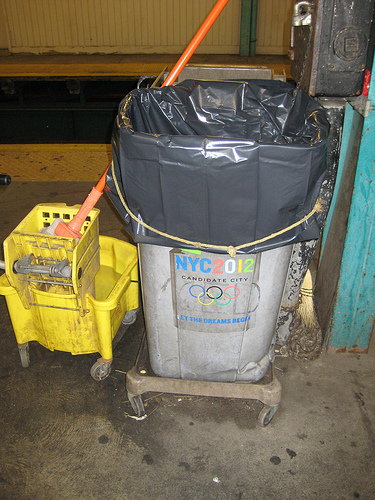

In [55]:
imagenet_val_path = paths.get('imagenet_val')

image_path = imagenet_val_path + '/n02747177/ILSVRC2012_val_00000422.JPEG'

# Load image
image = PILImage.open(image_path)

image

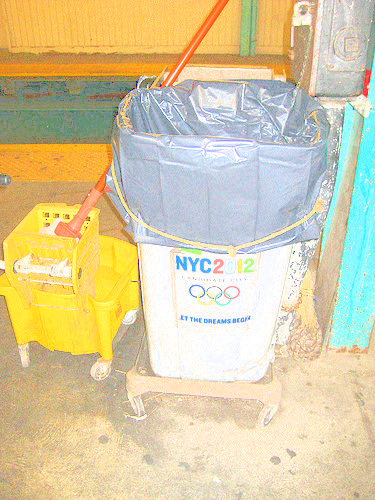

In [56]:
# Brightness
image_with_brightness = brightness(torch.tensor(np.array(image)).permute(2, 0, 1)).numpy().astype(np.uint8)

PILImage.fromarray(image_with_brightness.transpose(1, 2, 0))

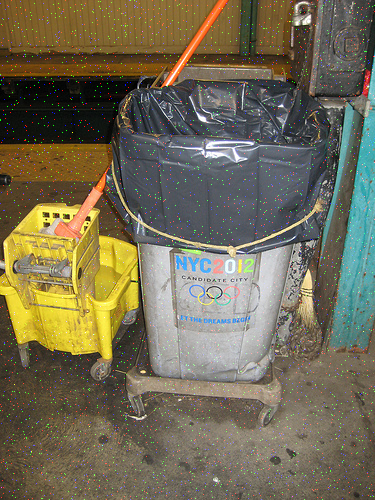

In [57]:
# Compare the original image with the image with noise
image_with_noise = gaussian_noise(torch.tensor(np.array(image)).permute(2, 0, 1)).permute(1, 2, 0).numpy().astype(np.uint8)

# Display the image with noise
PILImage.fromarray(image_with_noise)

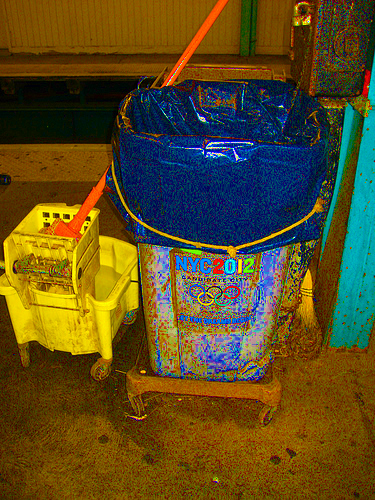

In [58]:
# Saturate
image_saturated = saturate(torch.tensor(np.array(image)).permute(2, 0, 1)).numpy().astype(np.uint8)

PILImage.fromarray(image_saturated.transpose(1, 2, 0))

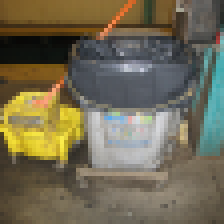

In [59]:
# Pixelate
image_pixelated = pixelate(torch.tensor(np.array(image)).permute(2, 0, 1)).permute(1, 2, 0).numpy().astype(np.uint8)

PILImage.fromarray(image_pixelated)